# EuroSAT Land-Cover Classification — A Comparative Deep Learning Study with Transfer Learning

# Notebook 08 — Final Evaluation & Error Analysis

## 1. Objective

This is the **final notebook** of the project. Notebooks 01–07 used only the training and validation sets; the 2,700-image test set has been held out from training, tuning, and model selection since the split was created in Notebook 02. (Notebook 02 constructed a `test_ds` pipeline object for completeness but never iterated over or evaluated it.) This notebook is the first, and only, one to read and evaluate the test set, to answer:

1. How well does the selected final model perform on unseen test data?
2. What do its test accuracy, loss, precision, recall, F1-score, and ROC-AUC look like?
3. Which classes are easiest/hardest, and which are most often confused?
4. What do the actual misclassified images look like, and what patterns (if any) appear in the errors?
5. How does test performance compare with validation performance?
6. What does the whole project — from a from-scratch baseline through transfer learning and fine-tuning — show, and what are its limitations?

No further model selection happens here. That decision (Section 3) was made entirely from Notebooks 03–07's validation results, before this notebook touched the test set at all.

## 2. Project Recap

| Notebook | What it did | Validation result (peak accuracy / minimum loss) |
|---|---|---:|
| 03 — Baseline CNN | 3-block CNN trained from scratch | 88.00% / 0.3607 |
| 04 — CNN Experiments | 9 controlled variations on the baseline (augmentation, BatchNorm, Dropout, depth, width, GAP, combined) | highest accuracy and lowest loss among the experiments: Dropout, 88.96% / 0.3327 |
| 05 — Transfer Learning Fundamentals | MobileNetV2, frozen-backbone feature extraction | 93.70% / 0.1814 |
| 06 — Transfer Learning Model Comparison | 6 frozen pretrained backbones compared | highest accuracy: ResNet50, 95.70% / 0.1567; lowest loss: EfficientNetB0, 0.1408 (with 95.26% accuracy) |
| 07 — Fine-Tuning | ResNet50 and EfficientNetB0, top 20% of backbone unfrozen | highest accuracy and lowest loss: EfficientNetB0, 96.67% / 0.1081 (ResNet50: 96.11% / 0.1300) |
| **08 — Final Evaluation** | **This notebook** — test-set evaluation of the model selected below | — |

Each validation entry is the peak validation accuracy and the minimum validation loss across epochs, which can come from different epochs. Every one of these results is a validation-set result. The test set has not appeared anywhere above.


## 3. Model Selection Decision

**Selected for final evaluation: EfficientNetB0 (Fine-Tuned), from Notebook 07.**

This is decided entirely from validation evidence already recorded in Notebooks 03–07 — the test set has not been used, and will not be built as a `tf.data.Dataset` in this notebook until Section 11.

| Model | Val Accuracy | Val Loss |
|---|---:|---:|
| Baseline CNN (03) | 88.00% | 0.3607 |
| Best Notebook 04 experiment (Dropout) | 88.96% | 0.3327 |
| ResNet50 — Feature Extraction (06) | 95.70% | 0.1567 |
| EfficientNetB0 — Feature Extraction (06) | 95.26% | 0.1408 |
| ResNet50 — Fine-Tuned (07) | 96.11% | 0.1300 |
| **EfficientNetB0 — Fine-Tuned (07)** | **96.67%** | **0.1081** |

(Peak validation accuracy and minimum validation loss across epochs. These are not necessarily the validation metrics of the restored model state that is evaluated on the test set; that restored model measured 96.48% / 0.1081 on the validation set in Section 10 and is compared with the test result in Section 18.)

EfficientNetB0 (Fine-Tuned) reached the highest validation accuracy and lowest validation loss recorded anywhere in this project. Beyond the headline numbers, Notebook 07's own epoch-by-epoch results showed EfficientNetB0 reaching its best validation loss at epoch 14 and best validation accuracy at epoch 15 — essentially still improving when training ended — whereas ResNet50 reached its best validation loss at epoch 1 and never improved on it in the remaining 5 epochs before `EarlyStopping` triggered. In other words, **EfficientNetB0 showed more sustained validation improvement during the fine-tuning run**, which is additional, specific evidence for this choice beyond the single best-epoch numbers.

ResNet50 (Fine-Tuned) is **not** carried into test evaluation. This notebook performs a final evaluation of one already-selected model, not a new comparison on the test set — running two models through the test set would blur that distinction and is exactly the kind of test-set-based model comparison this project's rules exclude.

## 4. Why Retraining Is Required

No notebook in this project has saved trained model weights to disk — every notebook so far has been standalone, rebuilding its own pipeline and retraining its own model(s) from scratch (Notebook 06 retrained MobileNetV2 fresh rather than reusing Notebook 05's run, for exactly this reason). Notebook 07's trained EfficientNetB0 weights exist only in that notebook's own session and are not available here.

This notebook therefore **retrains EfficientNetB0 using the identical two-stage procedure from Notebook 07** — Stage A (frozen-backbone feature extraction) followed by Stage B (fine-tuning: top 20% of backbone layers unfrozen, BatchNormalization layers kept frozen, learning rate 1e-5) — using only the training and validation sets, exactly as before. The test set plays no role in this retraining. Section 10 then checks, honestly, how closely this run reproduces Notebook 07's recorded numbers, before Section 11 moves on to the actual test evaluation.

## 5. Imports and Configuration

`DATASET_ROOT` below is a relative path: place the EuroSAT RGB dataset in `data/EuroSAT_RGB/` next to this notebook, or **change it to the location of the dataset on your machine before running this notebook.**

In [1]:
from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

In [ ]:
DATASET_ROOT = Path("data/EuroSAT_RGB")

CLASS_NAMES = [
    "AnnualCrop", "Forest", "HerbaceousVegetation",
    "Highway", "Industrial", "Pasture",
    "PermanentCrop", "Residential", "River",
    "SeaLake",
]

CLASS_TO_ID = {class_name: idx for idx, class_name in enumerate(CLASS_NAMES)}
EXPECTED_EXTENSIONS = {".jpg", ".jpeg"}

SEED = 42
IMAGE_SIZE = (128, 128)
IMG_SHAPE = IMAGE_SIZE + (3,)
NUM_CLASSES = 10
BATCH_SIZE = 32

EPOCHS = 15                    # same ceiling used throughout Notebooks 05-07
LR_FEATURE_EXTRACTION = 1e-3
LR_FINE_TUNE = 1e-5
UNFREEZE_FRACTION = 0.20

PREPROCESS_INPUT = tf.keras.applications.efficientnet.preprocess_input  # EfficientNetB0's own preprocessing (Section 7)

def set_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds(SEED)

## 6. Dataset, Split & Overlap Check

The same manifest and the same two-stage stratified 80/10/10 split (`SEED = 42`) used in every previous notebook. All three sets — `train_df`, `val_df`, `test_df` — are built here, but **only `train_df` and `val_df` are turned into a `tf.data.Dataset` before Section 11.** `test_df` stays a plain DataFrame (filenames and labels only, no images loaded) until then.

In [3]:
records = []
for class_name in CLASS_NAMES:
    class_dir = DATASET_ROOT / class_name
    for path in class_dir.iterdir():
        if path.is_file() and path.suffix.lower() in EXPECTED_EXTENSIONS:
            records.append((str(path), class_name, CLASS_TO_ID[class_name]))

manifest_df = pd.DataFrame(records, columns=["filepath", "class_name", "label"])

train_df, temp_df = train_test_split(
    manifest_df, test_size=0.20, stratify=manifest_df["label"], random_state=SEED,
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train:      {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test:       {len(test_df)}  (not loaded into a tf.data.Dataset until Section 11)")

Train:      21600
Validation: 2700
Test:       2700  (not loaded into a tf.data.Dataset until Section 11)


In [4]:
train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

train_val_overlap = len(train_paths & val_paths)
train_test_overlap = len(train_paths & test_paths)
val_test_overlap = len(val_paths & test_paths)

print(f"Train/Validation overlap: {train_val_overlap}")
print(f"Train/Test overlap:       {train_test_overlap}")
print(f"Validation/Test overlap:  {val_test_overlap}")

assert train_val_overlap == 0
assert train_test_overlap == 0
assert val_test_overlap == 0
print("\nNo filepath overlap between any of the three splits.")

Train/Validation overlap: 0
Train/Test overlap:       0
Validation/Test overlap:  0

No filepath overlap between any of the three splits.


## 7. TensorFlow Pipeline

Same pattern as Notebooks 05–07: images decoded, resized to 128×128, cast to `float32`, and passed through EfficientNetB0's own `preprocess_input` exactly once (EfficientNet's version is an intentional no-op — see Notebook 06, Section 5 — since the model has its own internal rescaling layer). Only `train_ds` and `val_ds` are built here.

In [5]:
def load_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)
    image = PREPROCESS_INPUT(image)
    return image, label


def make_dataset(df, shuffle):
    filepaths = df["filepath"].values
    labels = df["label"].values
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df, shuffle=False)

print("train_ds:", train_ds)
print("val_ds:  ", val_ds)

train_ds: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
val_ds:   <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


## 8. Rebuild Selected Model — Stage A (Feature Extraction)

Identical setup to Notebooks 05–07: frozen EfficientNetB0 backbone, `base_model(inputs, training=False)` to keep BatchNorm layers in inference mode, `GlobalAveragePooling2D → Dropout(0.2) → Dense(10, softmax)` head, Adam at `LR_FEATURE_EXTRACTION`.

In [6]:
set_seeds()

base_model = tf.keras.applications.EfficientNetB0(
    input_shape=IMG_SHAPE, include_top=False, weights="imagenet",
)
base_model.trainable = False

inputs = tf.keras.Input(shape=IMG_SHAPE)
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs, name="efficientnetb0_final")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_FEATURE_EXTRACTION),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

fe_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True,
)

fe_start = time.time()
fe_history = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    callbacks=[fe_early_stopping], shuffle=False, verbose=2,
)
fe_time_s = round(time.time() - fe_start, 1)

fe_history_df = pd.DataFrame(fe_history.history)
fe_history_df.index = fe_history_df.index + 1
fe_history_df.index.name = "epoch"

fe_best_val_acc = float(fe_history_df["val_accuracy"].max())
fe_best_val_acc_epoch = int(fe_history_df["val_accuracy"].idxmax())
fe_best_val_loss = float(fe_history_df["val_loss"].min())
fe_best_val_loss_epoch = int(fe_history_df["val_loss"].idxmin())

print(f"\nStage A: best val_accuracy={fe_best_val_acc:.2%} (epoch {fe_best_val_acc_epoch}), "
      f"best val_loss={fe_best_val_loss:.4f} (epoch {fe_best_val_loss_epoch}), time={fe_time_s}s")

Epoch 1/15
675/675 - 272s - 403ms/step - accuracy: 0.8693 - loss: 0.4555 - val_accuracy: 0.9226 - val_loss: 0.2464
Epoch 2/15
675/675 - 267s - 396ms/step - accuracy: 0.9237 - loss: 0.2391 - val_accuracy: 0.9363 - val_loss: 0.1989
Epoch 3/15
675/675 - 316s - 467ms/step - accuracy: 0.9347 - loss: 0.2037 - val_accuracy: 0.9393 - val_loss: 0.1760
Epoch 4/15
675/675 - 260s - 385ms/step - accuracy: 0.9389 - loss: 0.1860 - val_accuracy: 0.9422 - val_loss: 0.1715
Epoch 5/15
675/675 - 262s - 389ms/step - accuracy: 0.9425 - loss: 0.1759 - val_accuracy: 0.9419 - val_loss: 0.1629
Epoch 6/15
675/675 - 261s - 387ms/step - accuracy: 0.9456 - loss: 0.1672 - val_accuracy: 0.9437 - val_loss: 0.1548
Epoch 7/15
675/675 - 260s - 385ms/step - accuracy: 0.9461 - loss: 0.1622 - val_accuracy: 0.9404 - val_loss: 0.1590
Epoch 8/15
675/675 - 248s - 368ms/step - accuracy: 0.9479 - loss: 0.1533 - val_accuracy: 0.9456 - val_loss: 0.1530
Epoch 9/15
675/675 - 262s - 388ms/step - accuracy: 0.9473 - loss: 0.1521 - val_a

## 9. Stage B — Fine-Tuning

Same procedure as Notebook 07: the top 20% of backbone layers are unfrozen (by layer count), except any `BatchNormalization` layer, which stays frozen even within that unfrozen region; the model is recompiled at the much smaller `LR_FINE_TUNE`; training continues with the same `EarlyStopping` configuration.

In [7]:
base_model.trainable = True
freeze_until = int(len(base_model.layers) * (1 - UNFREEZE_FRACTION))
for i, layer in enumerate(base_model.layers):
    if i < freeze_until:
        layer.trainable = False
    else:
        layer.trainable = not isinstance(layer, tf.keras.layers.BatchNormalization)

n_unfrozen_layers = sum(1 for layer in base_model.layers if layer.trainable)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_FINE_TUNE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

ft_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True,
)

ft_start = time.time()
ft_history = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    callbacks=[ft_early_stopping], shuffle=False, verbose=2,
)
ft_time_s = round(time.time() - ft_start, 1)

ft_history_df = pd.DataFrame(ft_history.history)
ft_history_df.index = ft_history_df.index + 1
ft_history_df.index.name = "epoch"

ft_best_val_acc = float(ft_history_df["val_accuracy"].max())
ft_best_val_acc_epoch = int(ft_history_df["val_accuracy"].idxmax())
ft_best_val_loss = float(ft_history_df["val_loss"].min())
ft_best_val_loss_epoch = int(ft_history_df["val_loss"].idxmin())

total_params = model.count_params()
trainable_params = sum(int(tf.size(w)) for w in model.trainable_weights)

print(f"\nStage B ({n_unfrozen_layers} unfrozen backbone layers, lr={LR_FINE_TUNE}): "
      f"best val_accuracy={ft_best_val_acc:.2%} (epoch {ft_best_val_acc_epoch}), "
      f"best val_loss={ft_best_val_loss:.4f} (epoch {ft_best_val_loss_epoch}), "
      f"trainable={trainable_params:,}/{total_params:,}, time={ft_time_s}s")

Epoch 1/15
675/675 - 337s - 499ms/step - accuracy: 0.9600 - loss: 0.1223 - val_accuracy: 0.9533 - val_loss: 0.1300
Epoch 2/15
675/675 - 340s - 503ms/step - accuracy: 0.9637 - loss: 0.1085 - val_accuracy: 0.9570 - val_loss: 0.1266
Epoch 3/15
675/675 - 396s - 587ms/step - accuracy: 0.9646 - loss: 0.0999 - val_accuracy: 0.9581 - val_loss: 0.1200
Epoch 4/15
675/675 - 402s - 595ms/step - accuracy: 0.9672 - loss: 0.0917 - val_accuracy: 0.9589 - val_loss: 0.1184
Epoch 5/15
675/675 - 405s - 601ms/step - accuracy: 0.9695 - loss: 0.0890 - val_accuracy: 0.9615 - val_loss: 0.1143
Epoch 6/15
675/675 - 376s - 556ms/step - accuracy: 0.9719 - loss: 0.0804 - val_accuracy: 0.9607 - val_loss: 0.1136
Epoch 7/15
675/675 - 299s - 443ms/step - accuracy: 0.9738 - loss: 0.0751 - val_accuracy: 0.9633 - val_loss: 0.1108
Epoch 8/15
675/675 - 233s - 345ms/step - accuracy: 0.9750 - loss: 0.0722 - val_accuracy: 0.9641 - val_loss: 0.1120
Epoch 9/15
675/675 - 234s - 347ms/step - accuracy: 0.9775 - loss: 0.0658 - val_a

## 10. Validation Reproducibility / Sanity Check

This compares this notebook's fresh run against Notebook 07's recorded result — it is **not** a requirement the model must pass. If the numbers differ, that difference is reported as-is, not corrected toward the old value: Notebook 07's own Limitations already noted that Stage A is a separate run each time and that these experiments are single runs, so some run-to-run difference is expected, consistent with what Notebook 04 observed as well. In the run recorded below, the fresh run happened to match Notebook 07's numbers exactly (96.67% / 0.1081).

These numbers are *peak* values across epochs (peak validation accuracy and minimum validation loss), which can come from different epochs. The cell after this one is intended to evaluate the model state that will actually be tested, on the validation set only (its measured output is shown with that cell).

In [8]:
notebook_07_reference = {"Val Accuracy": 0.9667, "Val Loss": 0.1081}

print("Notebook 07 recorded result:      "
      f"{notebook_07_reference['Val Accuracy']:.2%} / {notebook_07_reference['Val Loss']:.4f}")
print("This notebook's fresh run (Stage B best): "
      f"{ft_best_val_acc:.2%} / {ft_best_val_loss:.4f}")
print(f"\nDifference: {(ft_best_val_acc - notebook_07_reference['Val Accuracy'])*100:+.2f} "
      f"percentage points accuracy, {ft_best_val_loss - notebook_07_reference['Val Loss']:+.4f} loss")
print("\nThis is reported as an observation about run-to-run variability, not adjusted or retrained to match.")

Notebook 07 recorded result:      96.67% / 0.1081
This notebook's fresh run (Stage B best): 96.67% / 0.1081

Difference: -0.00 percentage points accuracy, +0.0000 loss

This is reported as an observation about run-to-run variability, not adjusted or retrained to match.


### Validation check of the model state used for the test evaluation

`EarlyStopping` monitors `val_loss` with `restore_best_weights=True`, so the weights in `model` after Stage B are determined by validation loss, not necessarily by the epoch with the peak validation accuracy (for EfficientNetB0 in the Stage B log, the lowest validation loss was at epoch 14 and the peak accuracy at epoch 15). The cell below runs `model.evaluate` on the **validation set only** — no test data is touched.

**Result in the recorded run:** the restored model measured **96.48% validation accuracy and 0.1081 validation loss**. This matches the logged Stage B epoch-14 values (the epoch of lowest validation loss), not the epoch-15 peak-accuracy values (96.67%), which confirms that the model evaluated on the test set is the restored best-loss model.


In [9]:
# Validation-only check of the model state that Section 11 will evaluate on the test set.
val_loss_chk, val_acc_chk = model.evaluate(val_ds, verbose=0)

print(f"Validation loss of the model state used for the test evaluation:     {val_loss_chk:.4f}")
print(f"Validation accuracy of the model state used for the test evaluation: {val_acc_chk:.4%}")

print("\nFor reference, from the Stage B log in this notebook:")
print(f"  Peak validation accuracy: {ft_best_val_acc:.2%}")
print(f"  Minimum validation loss:  {ft_best_val_loss:.4f}")


Validation loss of the model state used for the test evaluation:     0.1081
Validation accuracy of the model state used for the test evaluation: 96.4815%

For reference, from the Stage B log in this notebook:
  Peak validation accuracy: 96.67%
  Minimum validation loss:  0.1081


## 11. Final Test Evaluation

**This is the first point in the project where the test dataset is actually read, iterated over, or evaluated for performance measurement.** Notebook 02 constructed a `test_ds` pipeline object for completeness, but it was never consumed during model development, and constructing a lazy `tf.data.Dataset` reads no images. In this notebook, `test_ds` is built here, using the exact same pipeline and preprocessing as `train_ds`/`val_ds` (Section 7) — same `IMAGE_SIZE`, same `preprocess_input` — and is not shuffled, consistent with `val_ds`.

In [10]:
test_ds = make_dataset(test_df, shuffle=False)

test_loss, test_accuracy = model.evaluate(test_ds, verbose=2)

print(f"\nTest Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

85/85 - 23s - 274ms/step - accuracy: 0.9659 - loss: 0.1148

Test Loss:     0.1148
Test Accuracy: 96.59%


In [11]:
y_proba = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_proba, axis=1)
y_true = test_df["label"].values

assert len(y_true) == len(y_pred) == len(test_df)
print(f"Predictions generated for all {len(y_true)} test images.")

Predictions generated for all 2700 test images.


## 12. Classification Report

Per-class precision, recall, F1-score, and support, plus two overall averages: **macro** (unweighted mean across the 10 classes — treats every class equally regardless of size) and **weighted** (mean weighted by each class's support — reflects overall performance accounting for class imbalance, relevant here since EuroSAT's classes range from 2,000 to 3,000 images).

In [12]:
report_dict = classification_report(
    y_true, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0,
)
report_df = pd.DataFrame(report_dict).T

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

report_df

                      precision    recall  f1-score   support

          AnnualCrop       0.97      0.94      0.95       300
              Forest       0.99      0.99      0.99       300
HerbaceousVegetation       0.94      0.97      0.95       300
             Highway       0.96      0.94      0.95       250
          Industrial       0.99      0.99      0.99       250
             Pasture       0.94      0.93      0.93       200
       PermanentCrop       0.94      0.94      0.94       250
         Residential       1.00      0.99      0.99       300
               River       0.95      0.96      0.96       250
             SeaLake       0.99      0.98      0.98       300

            accuracy                           0.97      2700
           macro avg       0.96      0.96      0.96      2700
        weighted avg       0.97      0.97      0.97      2700



,precision,recall,f1-score,support
AnnualCrop,0.965636,0.936667,0.950931,300.000000
Forest,0.986755,0.993333,0.990033,300.000000
HerbaceousVegetation,0.935897,0.973333,0.954248,300.000000
Highway,0.955466,0.944000,0.949698,250.000000
Industrial,0.988000,0.988000,0.988000,250.000000
Pasture,0.939086,0.925000,0.931990,200.000000
PermanentCrop,0.940239,0.944000,0.942116,250.000000
Residential,0.996656,0.993333,0.994992,300.000000
River,0.952381,0.960000,0.956175,250.000000
SeaLake,0.986622,0.983333,0.984975,300.000000


## 13. Multiclass ROC-AUC

With 10 classes, ROC-AUC is computed **one-vs-rest (OvR)**: for each class, that class is treated as "positive" and all others as "negative," an AUC is computed for that one-vs-rest problem, and the 10 resulting AUCs are then averaged. `average="macro"` weights every class equally; `average="weighted"` weights by class support — both are reported, mirroring the two averages in Section 12. This is not a binary-classification metric treated as multiclass; `roc_auc_score`'s own `multi_class="ovr"` multiclass machinery is used directly, with `y_proba` (the model's full 10-column softmax output) as input, not just the predicted class.

In [13]:
try:
    roc_auc_macro = roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro")
    roc_auc_weighted = roc_auc_score(y_true, y_proba, multi_class="ovr", average="weighted")
    print(f"Multiclass ROC-AUC (OvR, macro-averaged):    {roc_auc_macro:.4f}")
    print(f"Multiclass ROC-AUC (OvR, weighted-averaged): {roc_auc_weighted:.4f}")
except ValueError as e:
    print(f"ROC-AUC could not be calculated: {e}")

Multiclass ROC-AUC (OvR, macro-averaged):    0.9991
Multiclass ROC-AUC (OvR, weighted-averaged): 0.9991


## 14. Confusion Matrix

Rows are true classes, columns are predicted classes. Diagonal cells are correct predictions; off-diagonal cells are errors — the (row, column) value is how many test images of the row's true class were predicted as the column's class.

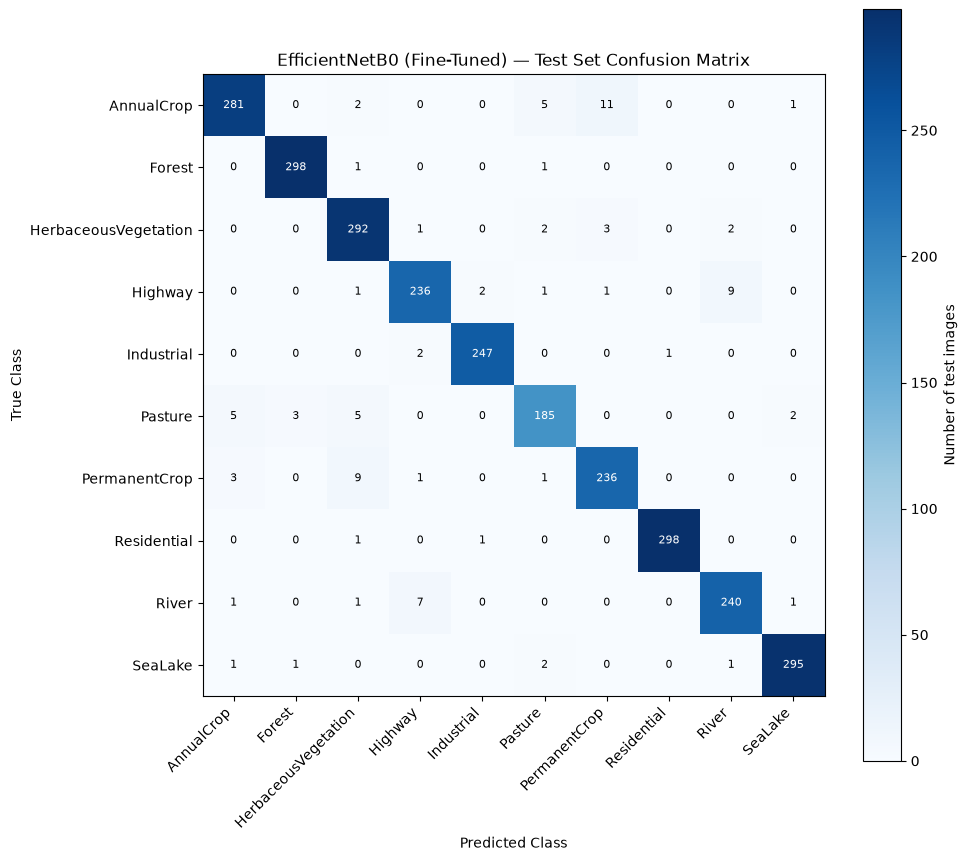

In [14]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")
ax.set_title("EfficientNetB0 (Fine-Tuned) — Test Set Confusion Matrix")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        value = cm[i, j]
        color = "white" if value > cm.max() / 2 else "black"
        ax.text(j, i, str(value), ha="center", va="center", color=color, fontsize=8)

fig.colorbar(im, ax=ax, label="Number of test images")
plt.tight_layout()
plt.show()

In [15]:
off_diagonal = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i, j] > 0:
            off_diagonal.append((cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]))

off_diagonal.sort(reverse=True)

print("Largest confusion pairs (true -> predicted : count):")
for count, true_cls, pred_cls in off_diagonal[:10]:
    print(f"  {true_cls} -> {pred_cls} : {count}")

Largest confusion pairs (true -> predicted : count):
  AnnualCrop -> PermanentCrop : 11
  PermanentCrop -> HerbaceousVegetation : 9
  Highway -> River : 9
  River -> Highway : 7
  Pasture -> HerbaceousVegetation : 5
  Pasture -> AnnualCrop : 5
  AnnualCrop -> Pasture : 5
  PermanentCrop -> AnnualCrop : 3
  Pasture -> Forest : 3
  HerbaceousVegetation -> PermanentCrop : 3


## 15. Per-Class Analysis

Per-class F1-scores range from 0.9320 (Pasture) to 0.9950 (Residential). All classes achieved an F1-score above 0.93, although performance was not uniform across classes.

**Lowest F1: Pasture** (precision 0.9391, recall 0.9250, F1 0.9320, support 200 — the smallest class in the test set). Precision and recall are both lower than for most other classes and close to each other, so there is no strong one-sided pattern: some true Pasture images were missed, and some images from other classes were predicted as Pasture, at similar rates. This matches Section 14's confusion list: Pasture is involved in four of the ten largest confusion pairs (`Pasture->HerbaceousVegetation`: 5, `Pasture->AnnualCrop`: 5, `AnnualCrop->Pasture`: 5, `Pasture->Forest`: 3). AnnualCrop and PermanentCrop each also appear in four of the ten largest pairs, so Pasture is not unique in this respect.

**Next lowest: AnnualCrop** (precision 0.9656, recall 0.9367, F1 0.9509) and **PermanentCrop** (precision 0.9402, recall 0.9440, F1 0.9421). AnnualCrop's recall is lower than its precision (93.67% vs 96.56%), meaning a noticeable number of true AnnualCrop images were predicted as another class — consistent with Section 14's largest single confusion pair, `AnnualCrop->PermanentCrop` (11 images), plus `AnnualCrop->Pasture` (5). PermanentCrop appears as the true class in `PermanentCrop->HerbaceousVegetation` (9, tied for the second-largest pair) and `PermanentCrop->AnnualCrop` (3). Seven of the ten largest confusion pairs are among AnnualCrop, PermanentCrop, HerbaceousVegetation, and Pasture (the only pair among them that involves Forest is `Pasture->Forest`, tied at 3 images with two other pairs) — so among the largest errors, these four vegetation/crop-type classes are mostly confused with each other.

**Highway and River** (F1 0.9497 and 0.9562) show a similar two-way pattern: `Highway->River` (9, tied for second-largest) and `River->Highway` (7, fourth-largest) run in both directions at similar magnitudes, so this is a mutual confusion between these two classes rather than one class being absorbed by the other.

**Highest F1: Residential (0.9950), Forest (0.9900), Industrial (0.9880), SeaLake (0.9850)** — all have precision and recall above 0.98 and within one percentage point of each other.

Overall, the classification report and the confusion matrix point the same way: the model's errors are concentrated among the vegetation/crop-type classes (Pasture, AnnualCrop, PermanentCrop, HerbaceousVegetation) and, separately, between Highway and River, while Residential, Industrial, Forest, and SeaLake had the highest F1-scores.


## 16. Error Analysis

A grid of actual misclassified test images, each labeled with its true class, predicted class, and the model's confidence (the predicted class's softmax probability) for that prediction.

Misclassified test images: 92 out of 2700 (3.41%)


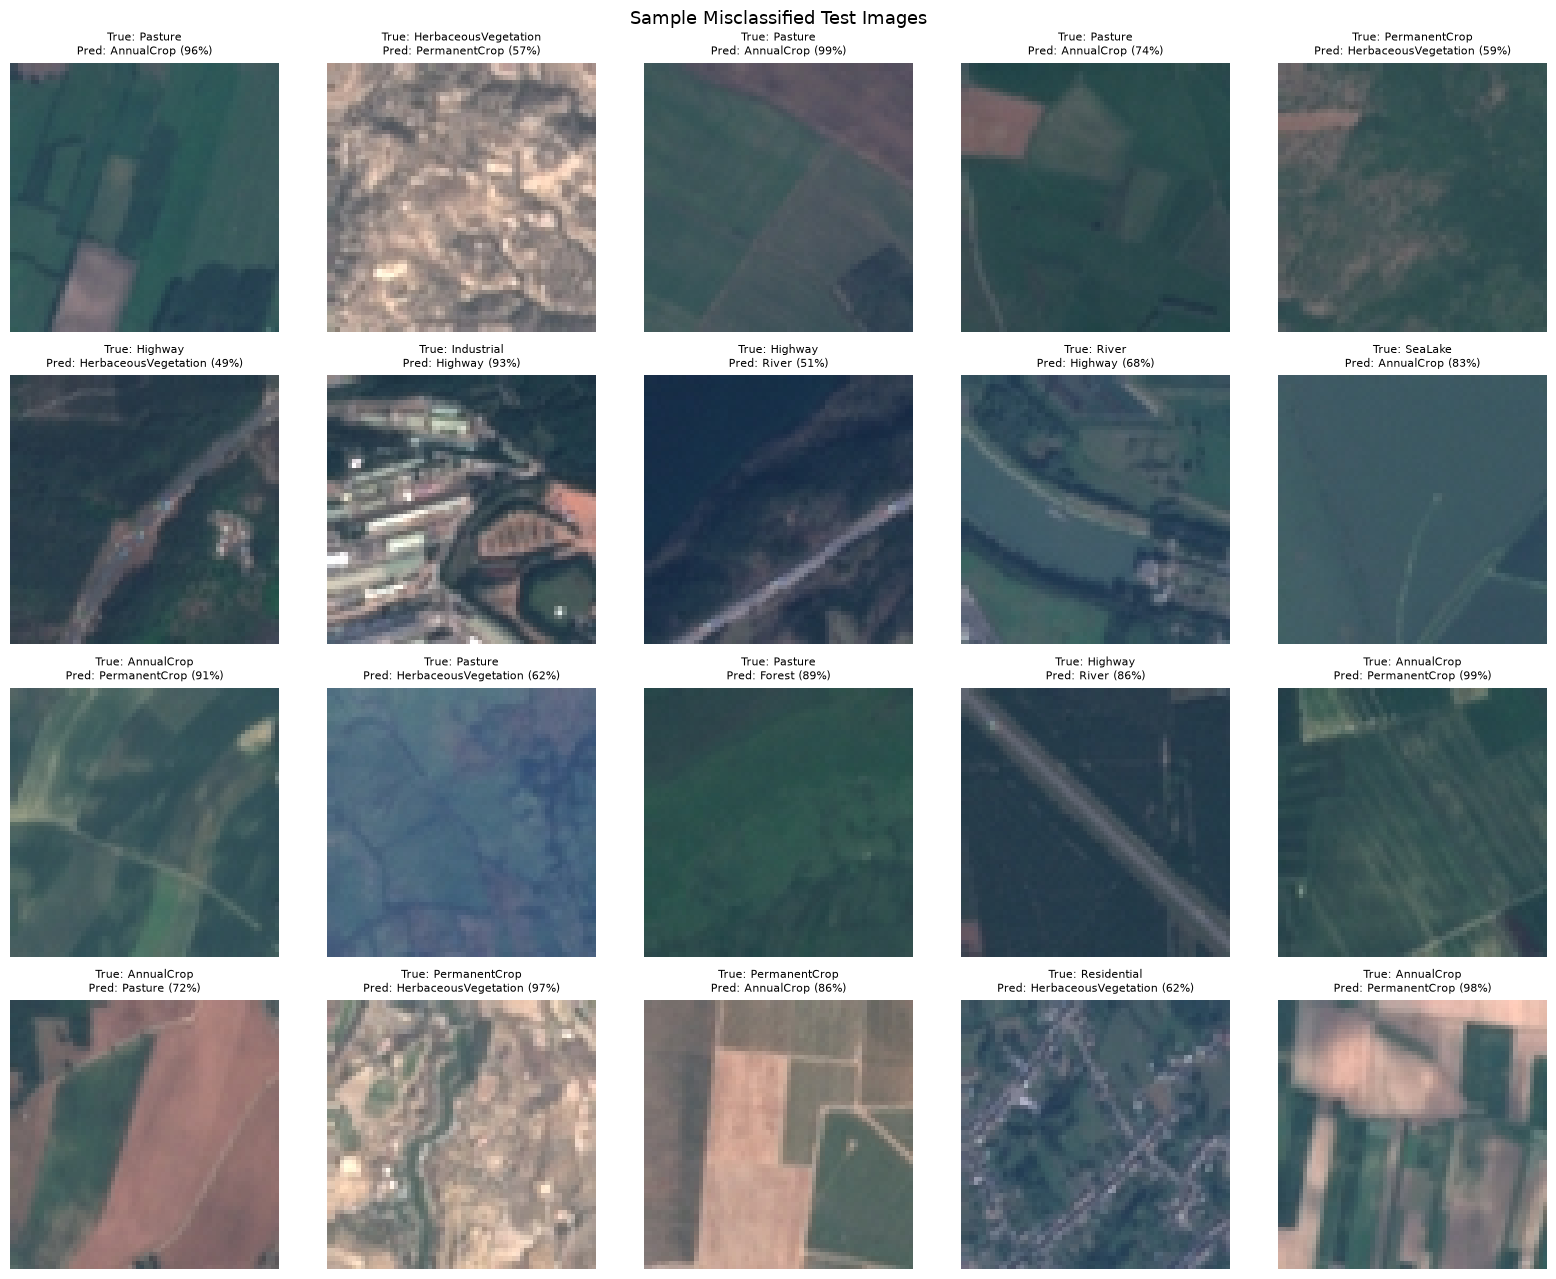

In [16]:
misclassified_idx = np.where(y_pred != y_true)[0]
print(f"Misclassified test images: {len(misclassified_idx)} out of {len(y_true)} "
      f"({len(misclassified_idx) / len(y_true):.2%})")

n_show = min(20, len(misclassified_idx))
rng = np.random.RandomState(SEED)
sample_idx = rng.choice(misclassified_idx, size=n_show, replace=False)
sample_idx.sort()

fig, axes = plt.subplots(4, 5, figsize=(16, 13))
axes = axes.flatten()

for ax, idx in zip(axes, sample_idx):
    filepath = test_df.loc[idx, "filepath"]
    true_cls = CLASS_NAMES[y_true[idx]]
    pred_cls = CLASS_NAMES[y_pred[idx]]
    confidence = y_proba[idx, y_pred[idx]]

    with tf.io.gfile.GFile(filepath, "rb") as f:
        img = tf.io.decode_jpeg(f.read(), channels=3).numpy()

    ax.imshow(img)
    ax.set_title(f"True: {true_cls}\nPred: {pred_cls} ({confidence:.0%})", fontsize=8)
    ax.axis("off")

for ax in axes[n_show:]:
    ax.axis("off")

plt.suptitle("Sample Misclassified Test Images", fontsize=13)
plt.tight_layout()
plt.show()

**Observation (based on the grid displayed above):** Using the true/predicted labels printed on the 20 sampled images, 12 are confusions among AnnualCrop, PermanentCrop, Pasture, and HerbaceousVegetation, 3 are Highway/River pairs (two `Highway->River`, one `River->Highway`), and the remaining 5 are other pairs (Highway→HerbaceousVegetation, Industrial→Highway, SeaLake→AnnualCrop, Residential→HerbaceousVegetation, Pasture→Forest). This is consistent with Section 14's largest off-diagonal cells rather than a scatter across all 10 classes, although 20 images drawn from 92 errors is a small sample.

Looking at the images themselves, the vegetation/crop errors are not all featureless fields. Several are smooth, low-contrast green or blue-green fields with few visible boundaries (for example, some of the true-Pasture images), while others show a patchwork of tan, pink, and green parcels (for example, several AnnualCrop images predicted as PermanentCrop) or irregular, mottled tan terrain (the HerbaceousVegetation→PermanentCrop and PermanentCrop→HerbaceousVegetation examples). In the three Highway/River pairs, the images show a long, narrow feature crossing the frame — a gray strip in the two Highway images and a wide, curved water band in the River image. One Residential image predicted as HerbaceousVegetation (62%) shows a street grid with buildings scattered among a lot of green vegetation, i.e. a mixed scene.

**Possible explanation:** Similar color tones and field layouts among crop, pasture, and herbaceous-vegetation images, together with the limited detail available in 64×64 source images (upsampled to 128×128), may make some of these classes hard to separate; likewise, a narrow linear feature on a darker background may look alike for a highway and a river. These are plausible readings of the sampled images, not confirmed causes — this notebook does not test which image properties actually drive the errors.

Keep these two separate: what is visible in the images is the observation; why it might cause confusion is the (unproven) explanation.


## 17. Confidence Analysis

Among the misclassified images, confidence can distinguish two different kinds of errors: a **high-confidence** wrong prediction suggests the model was confidently wrong (possibly a genuinely ambiguous or mislabeled image, or a real model weakness), while a **low-confidence** wrong prediction suggests the model itself was uncertain (the prediction was close to a toss-up, which is a milder kind of error). Confidence alone doesn't prove *which* of these explanations is correct for any single image — it's a signal worth combining with the actual image, not a verdict by itself.

This section does not evaluate calibration (for example with a reliability diagram or expected calibration error), so the predicted-class probabilities are used only to rank the sampled errors; they are not claimed to be calibrated probabilities. The two grids below are small illustrative samples of the 92 misclassified images, not an analysis of all of them.


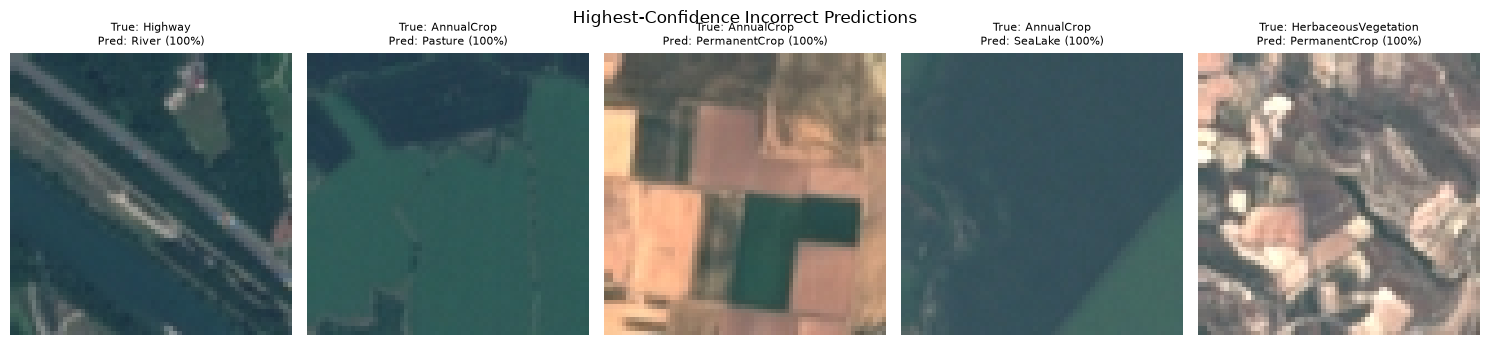

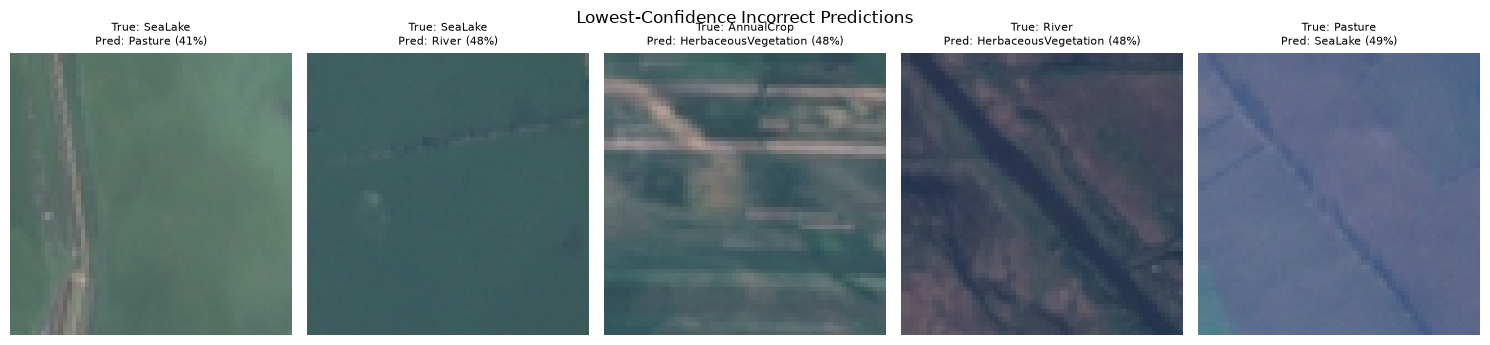

In [17]:
misclassified_confidences = y_proba[misclassified_idx, y_pred[misclassified_idx]]

high_conf_order = misclassified_idx[np.argsort(-misclassified_confidences)]
low_conf_order = misclassified_idx[np.argsort(misclassified_confidences)]

n_each = 5

def show_examples(indices, title):
    fig, axes = plt.subplots(1, len(indices), figsize=(3 * len(indices), 3.5))
    if len(indices) == 1:
        axes = [axes]
    for ax, idx in zip(axes, indices):
        filepath = test_df.loc[idx, "filepath"]
        true_cls = CLASS_NAMES[y_true[idx]]
        pred_cls = CLASS_NAMES[y_pred[idx]]
        confidence = y_proba[idx, y_pred[idx]]
        with tf.io.gfile.GFile(filepath, "rb") as f:
            img = tf.io.decode_jpeg(f.read(), channels=3).numpy()
        ax.imshow(img)
        ax.set_title(f"True: {true_cls}\nPred: {pred_cls} ({confidence:.0%})", fontsize=8)
        ax.axis("off")
    plt.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


show_examples(high_conf_order[:n_each], "Highest-Confidence Incorrect Predictions")
show_examples(low_conf_order[:n_each], "Lowest-Confidence Incorrect Predictions")

Looking at the two grids above (five images each):

**Examples from the highest-confidence grid.** The grid shows the five misclassified test images ranked highest by predicted-class probability. All five are displayed as 100% after rounding, so several errors are tied at this level and the grid is a sample of such cases rather than a strict top-five of distinct confidence values:
- *True Highway, predicted River:* diagonal gray strips run alongside a large dark blue-green area that could plausibly resemble water.
- *True AnnualCrop, predicted Pasture:* a large, smooth teal-green field with a darker region along the top.
- *True AnnualCrop, predicted PermanentCrop:* a patchwork of pink-tan parcels with a dark green L-shaped parcel.
- *True AnnualCrop, predicted SeaLake:* an almost uniform dark blue-green patch with very little texture, which looks water-like.
- *True HerbaceousVegetation, predicted PermanentCrop:* irregular, mottled tan, pink, and green terrain with no obvious parcel layout.

For some of these (AnnualCrop→SeaLake, Highway→River) the confident wrong prediction is at least visually understandable; for others, including the HerbaceousVegetation→PermanentCrop image, we cannot tell from the image alone why the model was so confident, or whether the image is genuinely borderline.

**Lowest-confidence errors (41%–49%, close to a toss-up):** all five images look hazy, blurry, or low-contrast in this sample. Two true-SeaLake images are teal-green with faint line features (a dark vertical strip; a dotted line), the AnnualCrop image is blurred with pale horizontal bands, the River image shows a dark diagonal strip on brownish-purple terrain, and the Pasture image has a hazy blue-purple tone with faint dark lines. This is consistent with these being closer calls, but five images per grid do not establish a general relationship between confidence and visual clarity.

This describes what these specific sampled images look like. It is not a claim that high confidence always corresponds to a visually justifiable error, or that low confidence always corresponds to an ambiguous image — a different sample could look different.


## 18. Validation vs. Test

The validation numbers from Notebook 07 (and Section 9) are *peak* values across fine-tuning epochs: the highest validation accuracy and the lowest validation loss, which came from different epochs. The model state evaluated on the test set is the one left in `model` after Stage B, and the validation-only check at the end of Section 10 (`model.evaluate(val_ds)`) measured its own validation metrics directly. The relevant values are:

| | Accuracy | Loss |
|---|---:|---:|
| Validation — peak accuracy / minimum loss across epochs (Notebook 07 and Section 9) | 96.67% | 0.1081 |
| Validation — logged Epoch 14 (epoch of lowest validation loss) | 96.48% | 0.1081 |
| Validation — restored model, measured by the Section 10 check | 96.48% | 0.1081 |
| Validation — logged Epoch 15 (epoch of peak validation accuracy) | 96.67% | 0.1097 |
| **Test (this notebook)** | **96.59%** | **0.1148** |

The measured validation metrics of the restored model (96.48% / 0.1081) match the logged Epoch 14 row, which confirms that `restore_best_weights=True` restored the lowest-validation-loss weights. Against that restored model, test accuracy is 0.11 percentage points higher (96.59% vs 96.48%) and test loss is 0.0067 higher (0.1148 vs 0.1081); against the peak validation accuracy (96.67%, a different epoch), test accuracy is 0.08 points lower. A gap this size is common between a validation set and a test set drawn from the same stratified split and class distribution, and does not by itself indicate overfitting: overfitting would need to show up as training performance continuing to improve while both validation and test performance move apart or degrade together, which is a different comparison than a single validation-vs-test snapshot. In this experiment, the fine-tuned EfficientNetB0's test-set performance was close to its validation-set performance, which is reasonable to report descriptively rather than as proof of general reliability.


## 19. No Data Leakage Verification

- **Test images were never used for training.** `test_df` was excluded from `train_ds`/`val_ds` at the split stage (Section 6) in every notebook from 02 onward, and the Section 6 overlap check above confirms zero filepath overlap between `test_df` and `train_df`/`val_df`. Notebook 02 constructed a `test_ds` pipeline object but never iterated over or evaluated it, and Notebooks 03–07 built no `test_ds` at all.
- **Test images were never used for hyperparameter tuning or model selection.** Every configuration choice in this project — architecture, unfreeze fraction, learning rates, epochs, the Section 3 model selection itself — was made using only validation-set results from Notebooks 03–07, before this notebook built `test_ds` at Section 11.
- **Test labels were only used starting at Section 11**, for computing the metrics in Sections 11–17.
- **Preprocessing was applied consistently**: `test_ds` (Section 11) uses the exact same `load_image`/`make_dataset` functions, `IMAGE_SIZE`, and `preprocess_input` as `train_ds`/`val_ds` (Section 7) — no separate or different preprocessing path was created for the test set.
- **No filepath overlap was detected between the test set and the training/validation sets**, as verified explicitly by the Section 6 overlap check (`train_test_overlap == 0`, `val_test_overlap == 0`). This is a filepath-level check; the project did not perform a content-level duplicate (hash) check across splits.
- **The validation-only check in Section 10** (`model.evaluate(val_ds)`) uses validation data only.

## 20. Final Project Conclusion

**Dataset.** EuroSAT RGB: 27,000 64×64 RGB satellite images across 10 land-cover classes, split 80/10/10 (21,600 / 2,700 / 2,700) with a stratified, seeded (`SEED = 42`) split verified to have zero filepath overlap between train, validation, and test sets.

**From-scratch CNN progression.** A simple 3-block CNN trained from scratch (Notebook 03) reached 88.00% validation accuracy. Notebook 04's nine controlled experiments showed that some changes offered small gains over this baseline — Dropout reached 88.96% — while others (BatchNorm alone, GAP alone, the combined-regularization runs) did not improve on it in these particular single runs; depth and width changes stayed close to baseline without a clear benefit given their added cost.

**Transfer Learning.** Moving to frozen ImageNet-pretrained backbones (Notebooks 05–06) produced a substantial jump: five of six architectures exceeded the from-scratch baseline, led by ResNet50 (95.70%) and EfficientNetB0 (95.26%), while transfer learning initially trained only a small classification head with the pretrained backbone frozen — far fewer trainable parameters than the baseline's 684,490, and a small number compared with the total parameters of the pretrained backbones.

**Fine-Tuning.** Unfreezing the top 20% of ResNet50's and EfficientNetB0's backbones (Notebook 07) improved both further — ResNet50 to 96.11%, EfficientNetB0 to 96.67% — though the two showed different training behavior: ResNet50's validation loss was lowest in its first fine-tuning epoch and did not improve afterward (a pattern that can indicate overfitting), while EfficientNetB0's validation loss and accuracy kept improving until close to its final epoch. EfficientNetB0 was selected for final evaluation based on the validation results observed during these previous experiments.

**Final Test Evaluation.** On the 2,700 held-out test images, the fine-tuned EfficientNetB0 achieved 96.59% accuracy (loss 0.1148) — 92 misclassified, a 3.41% error rate — close to its peak validation accuracy (96.67%) and minimum validation loss (0.1081); the restored model itself measured 96.48% / 0.1081 on the validation set (Section 10), i.e. the lowest-validation-loss Epoch 14 weights, so the test accuracy is 0.11 points above its validation accuracy. Macro F1 was 0.9643 and weighted F1 was 0.9659; macro and weighted multiclass ROC-AUC (one-vs-rest) were both 0.9991.

**Error Analysis.** Errors concentrated among the vegetation/crop-type classes — Pasture, AnnualCrop, PermanentCrop, and HerbaceousVegetation were confused with each other in 7 of the 10 largest confusion pairs (e.g. `AnnualCrop->PermanentCrop`: 11, `PermanentCrop->HerbaceousVegetation`: 9) — and, separately, between Highway and River (9 and 7 images respectively), which was a genuinely mutual, two-way confusion rather than one class dominating the other. Inspection of the sampled misclassified images was consistent with this pattern (12 of the 20 sampled errors were confusions among these four vegetation/crop classes and 3 were Highway/River pairs) and suggested that such images can look similar in color and field layout, with the Highway/River cases sharing a narrow linear feature crossing the frame; this is a limited-sample observation, not a confirmed cause. Residential, Industrial, Forest, and SeaLake had the highest F1-scores (0.98–0.995).

**Limitations.**
- All transfer-learning and fine-tuning experiments (Notebooks 05–08) used a single dataset (EuroSAT RGB) and a single train/validation/test split — results have not been checked against a different split or dataset.
- Most experiments across Notebooks 04–08 were single runs; Notebook 04 directly demonstrated that this project's training can show meaningful run-to-run variability, so individual close results elsewhere in the project should be read with that in mind.
- Transfer learning and fine-tuning used 128×128 input images rather than each architecture's native 224×224 resolution (Notebook 06, Section 4).
- Fine-tuning's unfreeze fraction (20%) and learning rate (1e-5) were each chosen once and explained, not tuned or searched over (Notebook 07, Section 15).
- Seed 42 is set throughout, but fully deterministic execution is not enforced in this environment, so exact repeated runs may differ; the results are those of the recorded runs.
- The overlap check verified filepaths only; no content-level duplicate (hash) check was performed across the train, validation, and test splits.
- Model selection for this notebook (Section 3) was based entirely on validation performance, as required — it is not guaranteed to be the configuration that would score highest on a different held-out set.
- Every transfer-learning and fine-tuning model started from ImageNet-pretrained initialization; none of this project's experiments measure how a non-ImageNet pretraining source might have performed.
- The visual error analysis in Sections 16–17 is based on a limited sample of misclassified images and is a plausible, not confirmed, reading of why those particular errors occurred.
- All training in this project ran within the computational limits of a single local machine, which shaped choices such as input resolution, epoch ceilings, and which architectures were fine-tuned (Notebook 07, Section 6).